<a href="https://colab.research.google.com/github/KruthikaVirupakshappa/DATA266-Lab1-Pair37/blob/jiayi-work/task2_sentiment/jiayi/src/Task2_Yelp_Sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import json
from pathlib import Path

MEMBER_NAME = "jiayi"
config_path = Path("task2_sentiment") / MEMBER_NAME / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

SID4         = 4253  # last four digits of your SJSU ID
SEED         = config["seed"] # torch.manual_seed, np.random.seed, random_state
SLICE        = SID4 % 1000   # start index of your dataset subset
HP_ID        = SID4 % 6      # your assigned hyperparameter arm, Table 0.1
CLS_A, CLS_B = (SID4 % 10), ((SID4 // 10) % 10)   # your two focus classes

MAX_VOCAB_SIZE = config["preprocessing"]["max_vocab_size"]
MIN_FREQ = config["preprocessing"]["min_freq"]
p = config["preprocessing"]["length_percentile"]
cap = config["preprocessing"]["max_len_cap"]

In [12]:
print(f"SID4: {SID4}, SEED: {SEED}, SLICE: {SLICE}, HP_ID: {HP_ID}, CLS_A, CLS_B: {CLS_A}, {CLS_B}")

SID4: 4253, SEED: 4253, SLICE: 253, HP_ID: 5, CLS_A, CLS_B: 3, 5


### Data Preprocessing

In [13]:
!pip install -q nltk

In [14]:
import random
import numpy as np
import torch
from pathlib import Path
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
import math
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
from datetime import datetime
import platform
from zoneinfo import ZoneInfo
import subprocess
import sys
from tqdm.auto import tqdm
import re
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer
from collections import Counter

In [22]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [37]:
# load shared data from download_.py
from datasets import load_from_disk
from pathlib import Path
from datasets import load_dataset

dataset_folder = Path("task2_sentiment/data/yelp_polarity")
data = load_from_disk(str(dataset_folder))

# inspect the original dataset
print(data)
print(data.keys())
print(data["train"].features)
print(data["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 560000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 38000
    })
})
dict_keys(['train', 'test'])
{'text': Value('string'), 'label': ClassLabel(names=['1', '2'])}
{'text': "Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has time for that or wants to deal with it?  I have run into this problem with many other doctors and I just don't get it.  You have office workers, you have patients with medical needs, why isn't anyone answering the phone?  It's incomprehensible and not work the aggravation.  It's with regret that I feel that I have to give Dr. Goldberg 2 stars.", 'label': 0}


In [25]:
# check and handle missing/malformed text or labels.
def valid_example(example):
    valid_text = isinstance(example["text"], str) and example["text"].strip() != ""
    valid_label = example["label"] in (0, 1)
    return valid_text and valid_label

train_before = len(data["train"])
test_before = len(data["test"])

train_raw = data["train"].filter(valid_example)
test_raw = data["test"].filter(valid_example)

print("Invalid train rows removed:", train_before - len(train_raw))
print("Invalid test rows removed:", test_before - len(test_raw))
print("Valid train rows:", len(train_raw))
print("Valid test rows:", len(test_raw))

Invalid train rows removed: 0
Invalid test rows removed: 0
Valid train rows: 560000
Valid test rows: 38000


Train class distribution
  label 0: 280,000 (50.00%)
  label 1: 280,000 (50.00%)


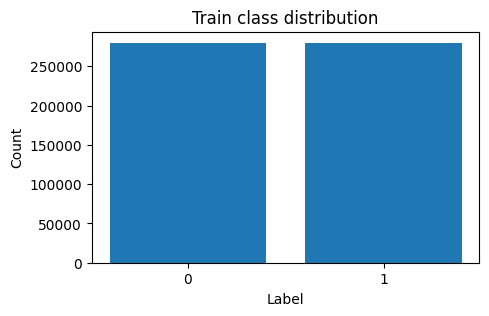

Test class distribution
  label 0: 19,000 (50.00%)
  label 1: 19,000 (50.00%)


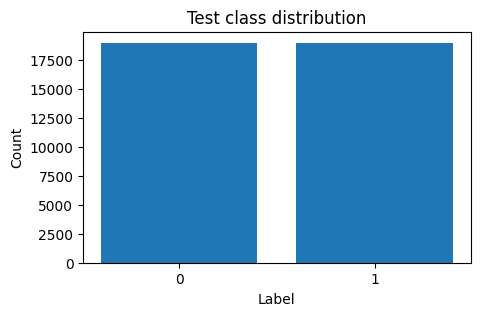

In [26]:
# class distribution and balance
def show_class_balance(split, name):
    labels = np.array(split["label"])
    values, counts = np.unique(labels, return_counts=True)
    total = len(labels)

    print(f"{name} class distribution")
    for value, count in zip(values, counts):
        print(f"  label {value}: {count:,} ({count / total:.2%})")

    plt.figure(figsize=(5, 3))
    plt.bar(values.astype(str), counts)
    plt.title(f"{name} class distribution")
    plt.xlabel("Label")
    plt.ylabel("Count")
    plt.show()

show_class_balance(train_raw, "Train")
show_class_balance(test_raw, "Test")


p50: 97 words
p90: 282 words
p95: 372 words
p99: 608 words
mean: 133.03
max: 1052


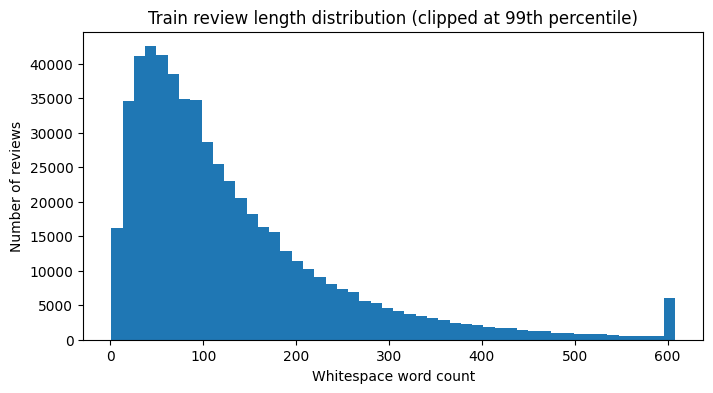

In [27]:
# review length distribution
# Keep the official Yelp test split untouched for final evaluation

raw_train_lengths = np.array([len(text.split()) for text in train_raw["text"]])

for p in [50, 90, 95, 99]:
    print(f"p{p}: {np.percentile(raw_train_lengths, p):.0f} words")
print("mean:", round(raw_train_lengths.mean(), 2))
print("max:", int(raw_train_lengths.max()))

p99 = int(np.percentile(raw_train_lengths, 99))
plt.figure(figsize=(8, 4))
plt.hist(np.clip(raw_train_lengths, 0, p99), bins=50)
plt.title("Train review length distribution (clipped at 99th percentile)")
plt.xlabel("Whitespace word count")
plt.ylabel("Number of reviews")
plt.show()


Train: 504000
Validation: 56000
Test: 38000
Train split class distribution
  label 0: 252,000 (50.00%)
  label 1: 252,000 (50.00%)


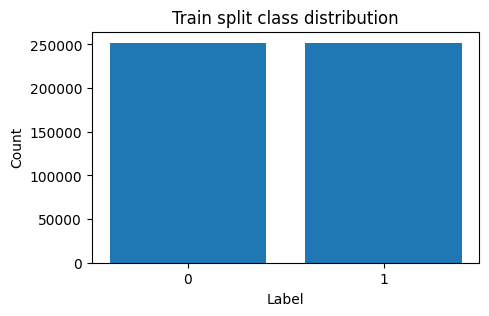

Validation split class distribution
  label 0: 28,000 (50.00%)
  label 1: 28,000 (50.00%)


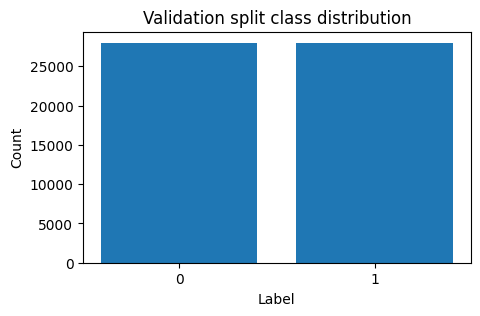

In [28]:
# stratify by label so train/validation keep the same class balance
# Keep the official Yelp test split untouched for final evaluation

all_indices = np.arange(len(train_raw))
all_labels = np.array(train_raw["label"])

train_idx, val_idx = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=all_labels,
)

train_ds = train_raw.select(train_idx.tolist())
val_ds = train_raw.select(val_idx.tolist())
test_ds = test_raw

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
show_class_balance(train_ds, "Train split")
show_class_balance(val_ds, "Validation split")

In [29]:
# lowercasing + regex cleanup + split()
# stopword removal + stemming

STOP_WORDS = set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never"}
stemmer = PorterStemmer()
USE_STEMMING = True


def clean_text(text):
    text = text.lower()

    # preserve common negation meaning before punctuation is removed
    text = re.sub(r"\bwon['’]t\b", "will not", text)
    text = re.sub(r"\bcan['’]t\b", "can not", text)
    text = re.sub(r"n['’]t\b", " not", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_text(cleaned_text):
    tokens = cleaned_text.split()
    tokens = [token for token in tokens if token not in STOP_WORDS]

    if USE_STEMMING:
        tokens = [stemmer.stem(token) for token in tokens]

    return tokens


def preprocess_text(text):
    cleaned = clean_text(text)
    return tokenize_text(cleaned)


for i in range(3):
    raw = train_ds[i]["text"]
    cleaned = clean_text(raw)
    tokens = tokenize_text(cleaned)

    print("RAW:", raw[:300])
    print("CLEANED:", cleaned[:300])
    print("TOKENS:", tokens[:40])
    print("-" * 80)

RAW: Hands down the best sushi I've ever had.  The other items are amazing too - kobe beef melts in your mouth.  Honestly one of the best meals in my entire life.  The ambiance is spectacular too, and the service is impeccable.  The waitstaff are friendly and full of good recommendations.  And it's at th
CLEANED: hands down the best sushi i ve ever had the other items are amazing too kobe beef melts in your mouth honestly one of the best meals in my entire life the ambiance is spectacular too and the service is impeccable the waitstaff are friendly and full of good recommendations and it s at the hard rock h
TOKENS: ['hand', 'best', 'sushi', 've', 'item', 'amaz', 'kobe', 'beef', 'melt', 'mouth', 'honestli', 'best', 'meal', 'entir', 'life', 'ambianc', 'spectacular', 'servic', 'impecc', 'waitstaff', 'friendli', 'good', 'recommend', 's', 'hard', 'rock', 'hotel', 'stick', 'tommi', 'lee', 'did']
--------------------------------------------------------------------------------
RAW: The new ch

In [30]:
# build a word-level vocabulary from the training split
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counts = Counter()
processed_lengths = []

for row in tqdm(train_ds, total=len(train_ds), desc="Building vocabulary"):
    tokens = preprocess_text(row["text"])
    word_counts.update(tokens)
    processed_lengths.append(len(tokens))

word_to_idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}

for word, count in word_counts.most_common(MAX_VOCAB_SIZE - 2):
    if count < MIN_FREQ:
        break
    word_to_idx[word] = len(word_to_idx)

idx_to_word = {idx: word for word, idx in word_to_idx.items()}

PAD_IDX = word_to_idx[PAD_TOKEN]
UNK_IDX = word_to_idx[UNK_TOKEN]
VOCAB_SIZE = len(word_to_idx)

print("Vocabulary size:", VOCAB_SIZE)
print("PAD index:", PAD_IDX, "UNK index:", UNK_IDX)
print("Most common words:", word_counts.most_common(20))

Building vocabulary:   0%|          | 0/504000 [00:00<?, ?it/s]

Vocabulary size: 30000
PAD index: 0 UNK index: 1
Most common words: [('not', 944567), ('n', 738899), ('s', 398289), ('place', 328537), ('food', 303181), ('good', 277031), ('like', 260575), ('time', 251013), ('just', 233251), ('order', 216211), ('did', 200601), ('servic', 195029), ('great', 189848), ('no', 171647), ('realli', 152257), ('tri', 143717), ('look', 122888), ('want', 122509), ('got', 120486), ('come', 119229)]


In [31]:
# use only the training split to choose a fixed sequence length
# 95th percentile covers most reviews; cap at 256 to keep training manageable

processed_lengths = np.array(processed_lengths)
p_len = int(np.percentile(processed_lengths, p))
MAX_LEN = min(p_len, cap)

print("Processed-token p50:", int(np.percentile(processed_lengths, 50)))
print("Processed-token p90:", int(np.percentile(processed_lengths, 90)))
print(f"Processed-token p{p}:", p_len)
print("MAX_LEN cap:", cap)
print("Final MAX_LEN used:", MAX_LEN)

Processed-token p50: 48
Processed-token p90: 140
Processed-token p99: 301
MAX_LEN cap: 256
Final MAX_LEN used: 256


In [32]:
# unknown words use <UNK>, and reviews are padded/truncated to MAX_LEN

def encode_tokens(tokens):
    return [word_to_idx.get(token, UNK_IDX) for token in tokens]


def encode_text(text):
    tokens = preprocess_text(text)
    ids = encode_tokens(tokens)[:MAX_LEN]
    length = len(ids)

    if length < MAX_LEN:
        ids = ids + [PAD_IDX] * (MAX_LEN - length)

    return ids, length

def encode_batch(batch):
    all_ids = []
    all_lengths = []

    for text in batch["text"]:
        ids, length = encode_text(text)
        all_ids.append(ids)
        all_lengths.append(length)

    return {
        "input_ids": all_ids,
        "length": all_lengths,
    }


train_encoded = train_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding train")
val_encoded = val_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding validation")
test_encoded = test_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding test")

sample = train_encoded[0]
print("Label:", sample["label"])
print("Encoded length before padding:", sample["length"])
print("First 30 token IDs:", sample["input_ids"][:30])
print("Fixed input length:", len(sample["input_ids"]))

Encoding train:   0%|          | 0/504000 [00:00<?, ? examples/s]

Encoding validation:   0%|          | 0/56000 [00:00<?, ? examples/s]

Encoding test:   0%|          | 0/38000 [00:00<?, ? examples/s]

Label: 1
Encoded length before padding: 31
First 30 token IDs: [224, 48, 175, 25, 182, 114, 2062, 230, 824, 608, 681, 48, 86, 392, 482, 676, 1434, 13, 2586, 2124, 80, 7, 95, 4, 214, 617, 105, 644, 5437, 2828]
Fixed input length: 256


In [33]:
from datasets import DatasetDict
from pathlib import Path

drive_dir = Path("/content/drive/MyDrive/DATA266_Lab1/task2_yelp_processed")
drive_dir.mkdir(parents=True, exist_ok=True)

encoded_dataset = DatasetDict({
    "train": train_encoded,
    "validation": val_encoded,
    "test": test_encoded
})

encoded_dataset.save_to_disk(str(drive_dir / "encoded_dataset"))

print("Saved encoded dataset to:")
print(drive_dir / "encoded_dataset")

Saving the dataset (0/2 shards):   0%|          | 0/504000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/56000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/38000 [00:00<?, ? examples/s]

Saved encoded dataset to:
/content/drive/MyDrive/DATA266_Lab1/task2_yelp_processed/encoded_dataset


In [34]:
with open(drive_dir / "word_to_idx.json", "w") as f:
    json.dump(word_to_idx, f)

print("Saved vocabulary to:")
print(drive_dir / "word_to_idx.json")

Saved vocabulary to:
/content/drive/MyDrive/DATA266_Lab1/task2_yelp_processed/word_to_idx.json


In [35]:
# demonstration of the shape produced by a randomly initialized embedding layer

EMBED_DIM = 128
embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=PAD_IDX)

sample_ids = torch.tensor([sample["input_ids"]], dtype=torch.long)
sample_emb = embedding(sample_ids)

print("Input ID shape:", sample_ids.shape)
print("Embedding output shape:", sample_emb.shape)

Input ID shape: torch.Size([1, 256])
Embedding output shape: torch.Size([1, 256, 128])


In [36]:
# full encoded dataset can be regenerated from the raw Yelp data

processed_dir = Path("task2_sentiment") / MEMBER_NAME / "data_processed"
processed_dir.mkdir(parents=True, exist_ok=True)

with open(processed_dir / "word_to_idx.json", "w") as f:
    json.dump(word_to_idx, f)

print("Saved:")
for p in sorted(processed_dir.iterdir()):
    print(" -", p)


Saved:
 - task2_sentiment/jiayi/data_processed/word_to_idx.json


## Model Training